# Day 4 — Hard Cases: Layouts, Tables, and Common JSON

**Module 4: Document Understanding**

**Goal:** Stress-test document extraction on difficult layouts: rotated scans, dense tables, merged table headers, varied invoice layouts, and multi-page documents. Then normalize provider outputs into one consistent JSON structure so they can be compared directly.



### 1. Install dependencies

In [1]:
!pip -q install pillow opencv-python-headless matplotlib pandas reportlab pdf2image

### 2. Imports

In [2]:
import json
import math
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas
from pdf2image import convert_from_path

print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


### 3. Create a hard-case test set

I will generate:
- a rotated invoice scan,
- an invoice with a merged title/header and a dense line-item table,
- a two-page invoice where the table continues on page 2,
- a second layout variant with different field placement.

These files let us test layout handling without uploading confidential business documents.

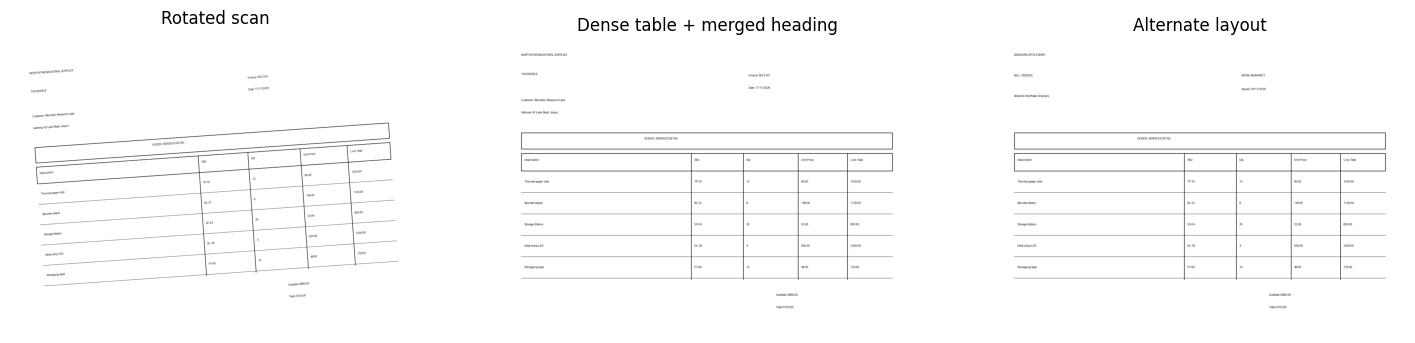

Created:
- alternate_layout_invoice.png
- dense_merged_header_invoice.png
- rotated_invoice.png


In [3]:
hard_dir = Path("module4_day4_hard_cases")
hard_dir.mkdir(exist_ok=True)

def get_fonts():
    try:
        return (
            ImageFont.truetype("DejaVuSans-Bold.ttf", 34),
            ImageFont.truetype("DejaVuSans-Bold.ttf", 23),
            ImageFont.truetype("DejaVuSans.ttf", 21),
        )
    except OSError:
        f = ImageFont.load_default()
        return f, f, f

title_font, head_font, body_font = get_fonts()

def draw_invoice_variant(path, rotated=False, alternate=False):
    img = Image.new("RGB", (1500, 1050), "white")
    d = ImageDraw.Draw(img)

    if not alternate:
        d.text((70, 55), "NORTHSTAR INDUSTRIAL SUPPLIES", fill="black", font=title_font)
        d.text((70, 125), "TAX INVOICE", fill="black", font=head_font)
        d.text((900, 130), "Invoice: NS-3107", fill="black", font=body_font)
        d.text((900, 175), "Date: 17/11/2026", fill="black", font=body_font)
        d.text((70, 220), "Customer: Meridian Research Labs", fill="black", font=body_font)
        d.text((70, 265), "Address: 42 Lake Road, Jaipur", fill="black", font=body_font)
    else:
        d.text((70, 55), "MERIDIAN OFFICE MART", fill="black", font=title_font)
        d.text((70, 130), "BILL / INVOICE", fill="black", font=head_font)
        d.text((70, 205), "Billed to: Northstar Analytics", fill="black", font=body_font)
        d.text((900, 130), "Ref No: MOM-8821", fill="black", font=body_font)
        d.text((900, 180), "Issued: 16/11/2026", fill="black", font=body_font)

    # Merged table heading across the full table width
    d.rectangle((70, 345, 1425, 405), outline="black", width=2)
    d.text((520, 360), "GOODS / SERVICES DETAIL", fill="black", font=head_font)

    # Column header row
    cols = [70, 690, 880, 1080, 1260, 1425]
    d.rectangle((70, 420, 1425, 485), outline="black", width=2)
    headers = ["Description", "SKU", "Qty", "Unit Price", "Line Total"]
    for i, h in enumerate(headers):
        d.text((cols[i] + 12, 438), h, fill="black", font=body_font)
    for x in cols[1:-1]:
        d.line((x, 420, x, 880), fill="black", width=2)

    rows = [
        ("Thermal paper rolls", "TP-10", "12", "85.00", "1020.00"),
        ("Barcode labels", "BL-22", "8", "140.00", "1120.00"),
        ("Storage folders", "SF-04", "25", "32.00", "800.00"),
        ("Desk lamp LED", "DL-18", "4", "550.00", "2200.00"),
        ("Packaging tape", "PT-09", "15", "48.00", "720.00"),
    ]
    y = 505
    for row in rows:
        d.line((70, y + 58, 1425, y + 58), fill="black", width=1)
        d.text((82, y + 12), row[0], fill="black", font=body_font)
        for i, value in enumerate(row[1:], start=1):
            d.text((cols[i] + 12, y + 12), value, fill="black", font=body_font)
        y += 78

    d.text((1000, 930), "Subtotal: 5860.00", fill="black", font=body_font)
    d.text((1000, 975), "Total: 6153.00", fill="black", font=head_font)

    if rotated:
        img = img.rotate(4, expand=True, fillcolor="white")
    img.save(path)
    return img

img_rotated = draw_invoice_variant(hard_dir / "rotated_invoice.png", rotated=True)
img_dense = draw_invoice_variant(hard_dir / "dense_merged_header_invoice.png")
img_alternate = draw_invoice_variant(hard_dir / "alternate_layout_invoice.png", alternate=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, im, label in zip(
    axes,
    [img_rotated, img_dense, img_alternate],
    ["Rotated scan", "Dense table + merged heading", "Alternate layout"]
):
    ax.imshow(im)
    ax.set_title(label)
    ax.axis("off")
plt.show()

print("Created:")
for p in sorted(hard_dir.iterdir()):
    print("-", p.name)

### 4. Create a two-page invoice PDF with a continuing table

This PDF deliberately places the table header on page 1 and continuation rows on page 2. Multi-page extraction should preserve the page association and row order rather than treating each page as an unrelated document.

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  poppler-utils
0 upgraded, 1 newly installed, 0 to remove and 49 not upgraded.
Need to get 212 kB of archives.
After this operation, 735 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 poppler-utils amd64 24.02.0-1ubuntu9.11 [212 kB]
Fetched 212 kB in 1s (238 kB/s)
Selecting previously unselected package poppler-utils.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up poppler-utils (24.02.0-1ubuntu9.11) ...
Processing triggers for man-db (2.12.0-4bu

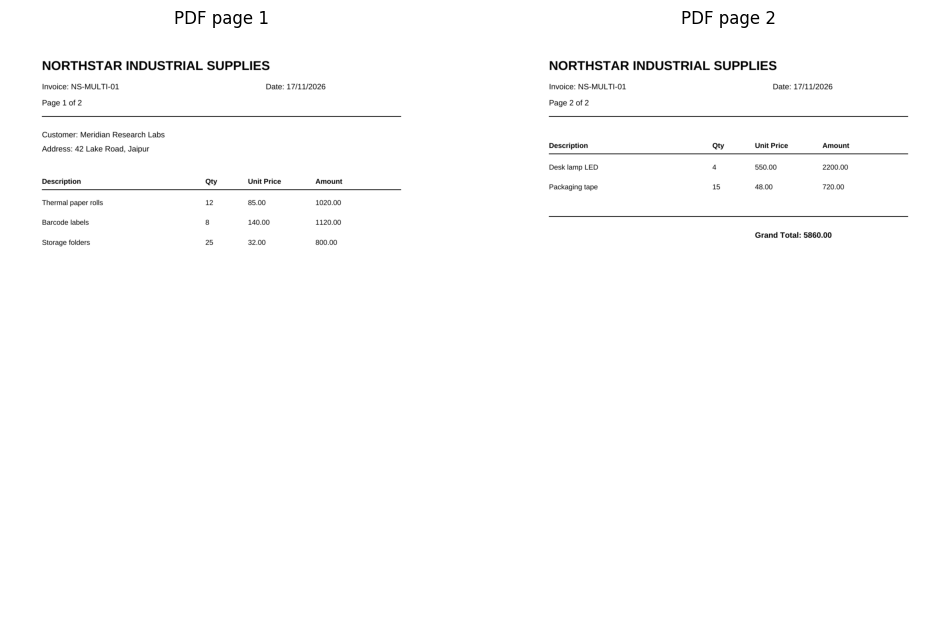

In [5]:
pdf_path = hard_dir / "two_page_invoice.pdf"
c = canvas.Canvas(str(pdf_path), pagesize=A4)
page_w, page_h = A4

def pdf_header(page_num):
    c.setFont("Helvetica-Bold", 18)
    c.drawString(45, page_h - 55, "NORTHSTAR INDUSTRIAL SUPPLIES")
    c.setFont("Helvetica", 11)
    c.drawString(45, page_h - 82, "Invoice: NS-MULTI-01")
    c.drawString(360, page_h - 82, "Date: 17/11/2026")
    c.drawString(45, page_h - 105, f"Page {page_num} of 2")
    c.line(45, page_h - 120, page_w - 45, page_h - 120)

def draw_table_header(y):
    c.setFont("Helvetica-Bold", 10)
    c.drawString(45, y, "Description")
    c.drawString(275, y, "Qty")
    c.drawString(335, y, "Unit Price")
    c.drawString(430, y, "Amount")
    c.line(45, y - 8, page_w - 45, y - 8)

pdf_header(1)
c.setFont("Helvetica", 11)
c.drawString(45, page_h - 150, "Customer: Meridian Research Labs")
c.drawString(45, page_h - 170, "Address: 42 Lake Road, Jaipur")
draw_table_header(page_h - 215)

page1_rows = [
    ("Thermal paper rolls", "12", "85.00", "1020.00"),
    ("Barcode labels", "8", "140.00", "1120.00"),
    ("Storage folders", "25", "32.00", "800.00"),
]
y = page_h - 245
c.setFont("Helvetica", 10)
for row in page1_rows:
    c.drawString(45, y, row[0]); c.drawString(275, y, row[1])
    c.drawString(335, y, row[2]); c.drawString(430, y, row[3])
    y -= 28
c.showPage()

pdf_header(2)
draw_table_header(page_h - 165)
page2_rows = [
    ("Desk lamp LED", "4", "550.00", "2200.00"),
    ("Packaging tape", "15", "48.00", "720.00"),
]
y = page_h - 195
c.setFont("Helvetica", 10)
for row in page2_rows:
    c.drawString(45, y, row[0]); c.drawString(275, y, row[1])
    c.drawString(335, y, row[2]); c.drawString(430, y, row[3])
    y -= 28
c.line(45, y - 10, page_w - 45, y - 10)
c.setFont("Helvetica-Bold", 11)
c.drawString(335, y - 40, "Grand Total: 5860.00")
c.save()
!apt-get update -qq
!apt-get install -y poppler-utils
print("Created PDF:", pdf_path.resolve())
pages = convert_from_path(str(pdf_path), dpi=130)
print("Pages rendered:", len(pages))

fig, axes = plt.subplots(1, len(pages), figsize=(12, 8))
if len(pages) == 1:
    axes = [axes]
for i, (ax, page) in enumerate(zip(axes, pages), start=1):
    ax.imshow(page)
    ax.set_title(f"PDF page {i}")
    ax.axis("off")
plt.show()

### 5. Deskew the rotated scan

A rotated scan can reduce line and table detection quality. Here we estimate the skew angle from the text pixels, then rotate the image to correct it. This is a simple demonstration; complex documents may need more robust orientation detection.

Estimated correction angle: 1.77 degrees


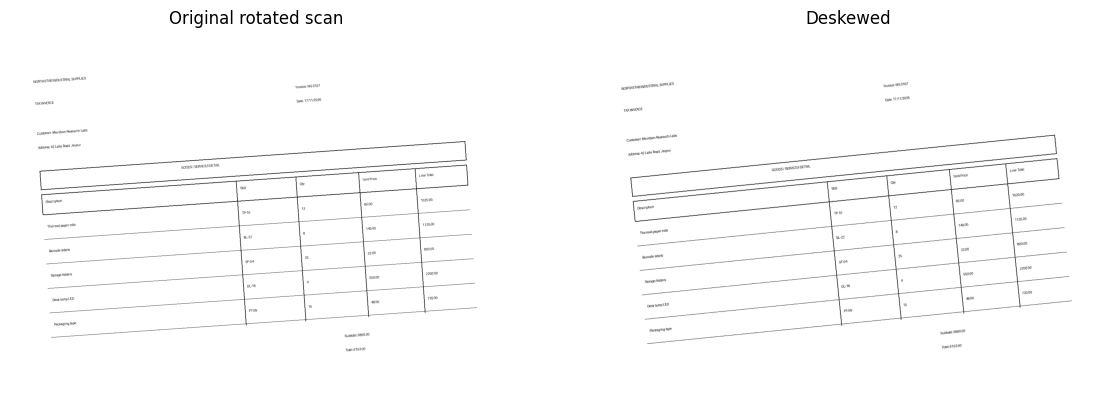

In [6]:
def estimate_and_deskew(pil_image):
    rgb = np.array(pil_image.convert("RGB"))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]

    coords = np.column_stack(np.where(binary > 0))
    if len(coords) < 20:
        return pil_image, 0.0

    angle = cv2.minAreaRect(coords)[-1]
    if angle < -45:
        angle = -(90 + angle)
    else:
        angle = -angle

    h, w = gray.shape
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    corrected = cv2.warpAffine(
        rgb, matrix, (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )
    return Image.fromarray(corrected), angle

deskewed, angle = estimate_and_deskew(img_rotated)
print("Estimated correction angle:", round(angle, 2), "degrees")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img_rotated); axes[0].set_title("Original rotated scan"); axes[0].axis("off")
axes[1].imshow(deskewed); axes[1].set_title("Deskewed"); axes[1].axis("off")
plt.show()

### 6. Inspect table structure with line detection

This lightweight OpenCV example detects horizontal and vertical rules in the dense invoice table. It illustrates how table structure is spatial, not just a sequence of words.

This is not a full table-recognition system: borderless tables, merged cells, and broken scan lines require more advanced approaches.

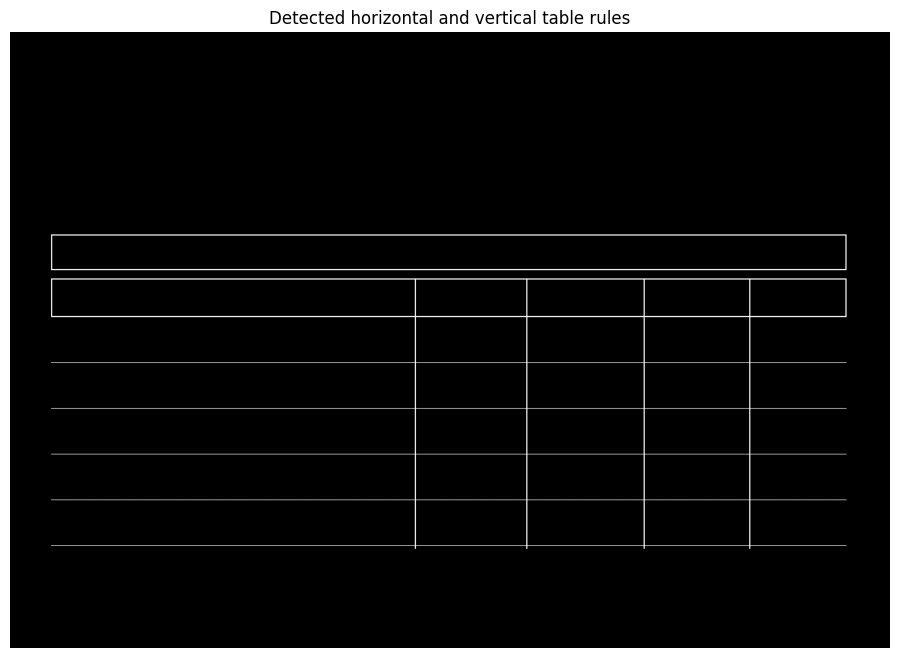

Horizontal line pixels: 17628
Vertical line pixels: 4196


In [7]:
gray = cv2.cvtColor(np.array(img_dense), cv2.COLOR_RGB2GRAY)
binary = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY_INV, 31, 10
)

horizontal_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (45, 1))
vertical_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 35))

horizontal_lines = cv2.morphologyEx(binary, cv2.MORPH_OPEN, horizontal_kernel)
vertical_lines = cv2.morphologyEx(binary, cv2.MORPH_OPEN, vertical_kernel)
table_lines = cv2.add(horizontal_lines, vertical_lines)

plt.figure(figsize=(14, 8))
plt.imshow(table_lines, cmap="gray")
plt.axis("off")
plt.title("Detected horizontal and vertical table rules")
plt.show()

print("Horizontal line pixels:", int(np.count_nonzero(horizontal_lines)))
print("Vertical line pixels:", int(np.count_nonzero(vertical_lines)))

### 7. Load Day 3 provider responses (optional)



In [8]:
from google.colab import files

uploaded = files.upload()
uploaded_json = {}

for filename, content in uploaded.items():
    if filename.lower().endswith(".json"):
        try:
            uploaded_json[filename] = json.loads(content.decode("utf-8"))
            print("Loaded:", filename)
        except Exception as error:
            print("Could not parse", filename, ":", error)

print("JSON files loaded:", list(uploaded_json.keys()))

KeyboardInterrupt: 

### 8. Normalize Azure Document Intelligence output

Azure's prebuilt invoice response is document-oriented and stores recognised fields in `documents[].fields`. The helper below extracts a consistent set of invoice fields and line items while retaining the raw JSON separately.

The code handles common Azure field representations but deliberately does not guess values that are absent.

In [9]:
def azure_value(field):
    if field is None:
        return None
    if isinstance(field, dict):
        # Raw SDK as_dict() usually represents typed values with keys such as valueString/valueNumber.
        for key in [
            "valueString", "valueNumber", "valueDate", "valueCurrency",
            "valueInteger", "value"
        ]:
            if key in field:
                value = field[key]
                if isinstance(value, dict) and "amount" in value:
                    return value["amount"]
                return value
        return field.get("content")
    return field

def normalize_azure(raw):
    docs = raw.get("documents", [])
    fields_out = {}
    line_items_out = []

    if docs:
        fields = docs[0].get("fields", {})
        aliases = {
            "supplier": ["VendorName", "SupplierName"],
            "customer": ["CustomerName", "BillTo"],
            "invoice_number": ["InvoiceId", "InvoiceNumber"],
            "invoice_date": ["InvoiceDate"],
            "due_date": ["DueDate"],
            "subtotal": ["SubTotal"],
            "tax": ["TotalTax"],
            "total": ["InvoiceTotal", "Total"],
        }
        for common_key, candidates in aliases.items():
            for candidate in candidates:
                if candidate in fields:
                    fields_out[common_key] = azure_value(fields[candidate])
                    break

        items_field = fields.get("Items", {})
        items_value = items_field.get("valueArray", []) if isinstance(items_field, dict) else []
        for item in items_value:
            item_obj = item.get("valueObject", {}) if isinstance(item, dict) else {}
            line = {}
            for source_key, target_key in [
                ("Description", "description"),
                ("Quantity", "quantity"),
                ("UnitPrice", "unit_price"),
                ("Amount", "amount"),
            ]:
                if source_key in item_obj:
                    line[target_key] = azure_value(item_obj[source_key])
            line_items_out.append(line)

    return {
        "provider": "Azure AI Document Intelligence",
        "document_type": "invoice",
        "fields": fields_out,
        "line_items": line_items_out,
        "tables": [],
        "pages": [],
    }

azure_raw = uploaded_json.get("azure_raw.json")
if azure_raw:
    azure_normalized = normalize_azure(azure_raw)
    print(json.dumps(azure_normalized, indent=2, ensure_ascii=False, default=str))
else:
    azure_normalized = None
    print("azure_raw.json not uploaded; Azure normalizer is ready to use.")

NameError: name 'uploaded_json' is not defined

### 9. Normalize AWS Textract AnalyzeExpense output

Textract `AnalyzeExpense` returns summary fields and line-item groups. The normalizer maps common types into the shared field names and keeps the original provider field names as well.

In [ ]:
def normalize_textract_expense(raw):
    fields_out = {}
    line_items_out = []

    for doc in raw.get("ExpenseDocuments", []):
        for summary in doc.get("SummaryFields", []):
            field_type = summary.get("Type", {}).get("Text")
            value = summary.get("ValueDetection", {}).get("Text")
            if field_type:
                fields_out[field_type] = value

        for group in doc.get("LineItemGroups", []):
            for item in group.get("LineItems", []):
                row = {}
                for field in item.get("LineItemExpenseFields", []):
                    field_type = field.get("Type", {}).get("Text", "OTHER")
                    value = field.get("ValueDetection", {}).get("Text")
                    row[field_type] = value
                line_items_out.append(row)

    aliases = {
        "supplier": ["VENDOR_NAME"],
        "customer": ["RECEIVER_NAME"],
        "invoice_number": ["INVOICE_RECEIPT_ID"],
        "invoice_date": ["INVOICE_RECEIPT_DATE"],
        "subtotal": ["SUBTOTAL"],
        "tax": ["TAX"],
        "total": ["TOTAL"],
    }
    common_fields = {}
    for common_key, candidates in aliases.items():
        for candidate in candidates:
            if candidate in fields_out:
                common_fields[common_key] = fields_out[candidate]
                break

    return {
        "provider": "AWS Textract AnalyzeExpense",
        "document_type": "invoice",
        "fields": common_fields,
        "provider_fields": fields_out,
        "line_items": line_items_out,
        "tables": [],
        "pages": [],
    }

aws_expense_raw = uploaded_json.get("aws_analyze_expense_raw.json")
if aws_expense_raw:
    aws_expense_normalized = normalize_textract_expense(aws_expense_raw)
    print(json.dumps(aws_expense_normalized, indent=2, ensure_ascii=False, default=str))
else:
    aws_expense_normalized = None
    print("aws_analyze_expense_raw.json not uploaded; Textract normalizer is ready to use.")

### 10. Preserve Textract table structure

For `AnalyzeDocument` responses, Textract represents tables as TABLE, CELL, and related blocks connected by relationships. This helper reconstructs a simple row/column grid from CELL blocks and retains page number and cell coordinates.

Merged cells and complex multi-page table continuation need additional reconciliation; do not assume this basic grid reconstruction resolves every case.

In [ ]:
def textract_table_grids(raw):
    blocks = raw.get("Blocks", [])
    tables = []

    for table in [b for b in blocks if b.get("BlockType") == "TABLE"]:
        child_ids = []
        for rel in table.get("Relationships", []):
            if rel.get("Type") == "CHILD":
                child_ids.extend(rel.get("Ids", []))

        cells = [
            b for b in blocks
            if b.get("BlockType") == "CELL" and b.get("Id") in child_ids
        ]
        if not cells:
            continue

        max_row = max(cell.get("RowIndex", 0) for cell in cells)
        max_col = max(cell.get("ColumnIndex", 0) for cell in cells)
        grid = [["" for _ in range(max_col)] for _ in range(max_row)]

        block_by_id = {b.get("Id"): b for b in blocks}
        for cell in cells:
            text_parts = []
            for rel in cell.get("Relationships", []):
                if rel.get("Type") == "CHILD":
                    for child_id in rel.get("Ids", []):
                        child = block_by_id.get(child_id, {})
                        if child.get("BlockType") == "WORD":
                            text_parts.append(child.get("Text", ""))
            r = cell.get("RowIndex", 1) - 1
            c = cell.get("ColumnIndex", 1) - 1
            grid[r][c] = " ".join(text_parts)

        tables.append({
            "page": table.get("Page"),
            "row_count": max_row,
            "column_count": max_col,
            "cells": grid,
        })
    return tables

textract_tables_raw = uploaded_json.get("aws_analyze_document_forms_tables_raw.json")
if textract_tables_raw:
    table_grids = textract_table_grids(textract_tables_raw)
    print(json.dumps(table_grids, indent=2, ensure_ascii=False))
else:
    table_grids = []
    print("No Textract FORMS + TABLES raw response uploaded.")

### 11. Define the common schema and add page-aware table data

For this module, use the following common structure:

```json
{
  "provider": "provider name",
  "document_type": "invoice",
  "fields": {},
  "line_items": [],
  "tables": [],
  "pages": []
}
```

- `fields` stores document-level key-value pairs.
- `line_items` stores normalized invoice items.
- `tables` stores table grids with page numbers.
- `pages` records page-level text or page metadata when available.

Keep raw provider responses separately. This common structure makes later scoring easier without discarding provider-specific evidence.

In [ ]:
common_results = []

if azure_normalized is not None:
    common_results.append(azure_normalized)

if aws_expense_normalized is not None:
    common_results.append(aws_expense_normalized)

if table_grids:
    # Attach the Textract table grids to the AWS result if it exists.
    aws_table_result = next(
        (x for x in common_results if x["provider"] == "AWS Textract AnalyzeExpense"),
        None
    )
    if aws_table_result is not None:
        aws_table_result["tables"] = table_grids
    else:
        common_results.append({
            "provider": "AWS Textract AnalyzeDocument",
            "document_type": "invoice",
            "fields": {},
            "line_items": [],
            "tables": table_grids,
            "pages": [],
        })

print("Normalized provider results:", len(common_results))
for result in common_results:
    print(result["provider"], "| fields:", len(result["fields"]),
          "| line items:", len(result["line_items"]),
          "| tables:", len(result["tables"]))

### 12. Fallback example: test the common schema without cloud outputs

If you did not run the cloud APIs, this small example lets you verify the schema shape. These are **known values from the synthetic document**, not provider predictions. Do not use this fallback as an accuracy result.

In [10]:
schema_example = {
    "provider": "Synthetic ground truth example (not model output)",
    "document_type": "invoice",
    "fields": {
        "invoice_number": "NS-3107",
        "invoice_date": "17/11/2026",
        "supplier": "NORTHSTAR INDUSTRIAL SUPPLIES",
        "customer": "Meridian Research Labs",
        "subtotal": "5860.00",
        "total": "6153.00"
    },
    "line_items": [
        {"description": "Thermal paper rolls", "sku": "TP-10", "quantity": "12", "unit_price": "85.00", "amount": "1020.00"},
        {"description": "Barcode labels", "sku": "BL-22", "quantity": "8", "unit_price": "140.00", "amount": "1120.00"},
        {"description": "Storage folders", "sku": "SF-04", "quantity": "25", "unit_price": "32.00", "amount": "800.00"},
        {"description": "Desk lamp LED", "sku": "DL-18", "quantity": "4", "unit_price": "550.00", "amount": "2200.00"},
        {"description": "Packaging tape", "sku": "PT-09", "quantity": "15", "unit_price": "48.00", "amount": "720.00"}
    ],
    "tables": [],
    "pages": [{"page": 1}, {"page": 2}]
}

print(json.dumps(schema_example, indent=2))

{
  "provider": "Synthetic ground truth example (not model output)",
  "document_type": "invoice",
  "fields": {
    "invoice_number": "NS-3107",
    "invoice_date": "17/11/2026",
    "supplier": "NORTHSTAR INDUSTRIAL SUPPLIES",
    "customer": "Meridian Research Labs",
    "subtotal": "5860.00",
    "total": "6153.00"
  },
  "line_items": [
    {
      "description": "Thermal paper rolls",
      "sku": "TP-10",
      "quantity": "12",
      "unit_price": "85.00",
      "amount": "1020.00"
    },
    {
      "description": "Barcode labels",
      "sku": "BL-22",
      "quantity": "8",
      "unit_price": "140.00",
      "amount": "1120.00"
    },
    {
      "description": "Storage folders",
      "sku": "SF-04",
      "quantity": "25",
      "unit_price": "32.00",
      "amount": "800.00"
    },
    {
      "description": "Desk lamp LED",
      "sku": "DL-18",
      "quantity": "4",
      "unit_price": "550.00",
      "amount": "2200.00"
    },
    {
      "description": "Packaging ta

### 13. Save normalized outputs

Save the common JSON records and a small CSV summary. These files will be useful for Day 5 evaluation.

In [12]:
day4_dir = Path("module4_day4_outputs")
day4_dir.mkdir(exist_ok=True)

common_results = [{
    "provider": "synthetic_examples",
    "fields": {
        "invoice_number": "NS-MULTI-01",
        "customer": "Meridian Research Labs",
        "date": "17/11/2026",
        "grand_total": 5860.00
    },
    "line_items": [
        {"description": "Thermal paper rolls", "quantity": 12, "amount": 1020.00},
        {"description": "Barcode labels", "quantity": 8, "amount": 1120.00},
        {"description": "Storage folders", "quantity": 25, "amount": 800.00},
        {"description": "Desk lamp LED", "quantity": 4, "amount": 2200.00},
        {"description": "Packaging tape", "quantity": 15, "amount": 720.00}
    ],
    "tables": []
}]

for result in common_results:
    safe_name = re.sub(r"[^a-z0-9]+", "_", result["provider"].lower()).strip("_")
    (day4_dir / f"{safe_name}_common.json").write_text(
        json.dumps(result, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

summary_rows = [{
    "provider": result["provider"],
    "field_count": len(result["fields"]),
    "line_item_count": len(result["line_items"]),
    "table_count": len(result["tables"])
} for result in common_results]

pd.DataFrame(summary_rows).to_csv(
    day4_dir / "normalization_summary.csv", index=False
)

print("Saved outputs:")
for path in sorted(day4_dir.iterdir()):
    print("-", path.name)

Saved outputs:
- normalization_summary.csv
- synthetic_examples_common.json
